# BO vs CMA-ES: Active-Subspace Pilot Framework

This notebook implements the experiment around the following separation:

1. **Configuration** defines the experiment and solver settings.
2. **Problem generation** uses the master seed to generate and freeze all problem instances first.
3. **Run specifications** pair each frozen problem with each solver and a deterministic solver seed.
4. **`run_experiment`** executes exactly one `(problem, solver, solver_seed)` specification.
5. **Raw results** are saved immediately to `data/` so plotting never requires rerunning optimization.
6. **Analysis/plotting** reloads saved files and derives best-so-far curves and summaries.

The ambient domain is the unit ball
$$
B_d=\{x\in\mathbb R^d:\|x\|_2\le 1\},
$$
and every ambient objective has
$$
f(x)=g(A^\top x),\qquad A^\top A=I_2.
$$

Solvers: random search, isotropic-RBF BO, ARD-RBF BO, oracle BO, and CMA-ES.

In [1]:
# If needed in a fresh environment:
# %pip install numpy scipy pandas matplotlib scikit-learn cma

import json
import platform
import time
import warnings
from dataclasses import asdict, dataclass, field
from pathlib import Path

import cma
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn
from scipy.optimize import minimize, check_grad
from scipy.linalg import cho_solve
from scipy.stats import norm
from sklearn.exceptions import ConvergenceWarning
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel as C, RBF

warnings.filterwarnings('ignore', category=ConvergenceWarning)

## 1. Configuration

`n_eval` is derived from `budget - n_init_pts`; it is not independently configurable. The pilot defaults to `d=(5,20)`. Change `dimensions` to `(2,5,10,20)` for the main experiment.

In [2]:
@dataclass
class BOConfig:
    n_gp_restarts: int = 0       # Additional GP log-marginal-likelihood restarts
    n_candidates: int = 1500      # Feasible random candidates used before local EI optimization
    n_acq_starts: int = 1        # SLSQP multi-start count
    acq_maxiter: int = 20       # Maximum SLSQP iterations per start
    acq_ftol: float = 1e-6       # SLSQP tolerance
    alpha: float = 1e-8          # Fixed numerical jitter for deterministic objectives
    length_scale_init: float = 0.5
    length_scale_bounds: tuple = (1e-3, 1e3)
    signal_init: float = 1.0
    signal_bounds: tuple = (1e-3, 1e3)

@dataclass
class CMAConfig:
    sigma0: float = 0.5          # Initial global CMA-ES step size
    popsize: int | None = None   # None = PyCMA default

@dataclass
class ExperimentConfig:
    objectives: tuple = ('norm',) # 'branin')
    dimensions: tuple = (2,)# 5, 10, 20)  # Pilot; use (2, 5, 10, 20) for main experiment
    
    k: int = 2                   # Effective dimension
    n_init_sets: int = 1         # Number of X_init sets
    n_rotations: int = 1         # Number of A: orthogonal matrices
    budget: int = 150            # Total true objective evaluations, including X_init
    
    n_inclusion: int = 1         # Redundant variable, explicit for readability
    n_init_pts: int = 2          # Size of X_init
    seed: int = 42   
    
    domain: str = 'unit_ball'
    data_dir: str = '../data_smoke'
    bo: BOConfig = field(default_factory=BOConfig)
    cma: CMAConfig = field(default_factory=CMAConfig)

    @property
    def n_eval(self):
        return self.budget - self.n_init_pts

cfg = ExperimentConfig()
assert cfg.k == 2
assert cfg.n_inclusion == 1
assert 0 < cfg.n_init_pts < cfg.budget
assert cfg.bo.n_candidates >= cfg.bo.n_acq_starts >= 1
print(cfg)
print('Remaining evaluations after initialization:', cfg.n_eval)

ExperimentConfig(objectives=('norm',), dimensions=(2,), k=2, n_init_sets=1, n_rotations=1, budget=150, n_inclusion=1, n_init_pts=2, seed=42, domain='unit_ball', data_dir='../data_smoke', bo=BOConfig(n_gp_restarts=0, n_candidates=1500, n_acq_starts=1, acq_maxiter=20, acq_ftol=1e-06, alpha=1e-08, length_scale_init=0.5, length_scale_bounds=(0.001, 1000.0), signal_init=1.0, signal_bounds=(0.001, 1000.0)), cma=CMAConfig(sigma0=0.5, popsize=None))
Remaining evaluations after initialization: 148


## 2. Domain and objectives

Uniform sampling from the unit ball uses
$$
w\sim N(0,I_d),\quad v=w/\|w\|,\quad r=U^{1/d},\quad x=rv,
$$
with $U\sim\mathrm{Uniform}(0,1)$.

For Branin, its conventional rectangle $[-5,10]\times[0,15]$ is affinely represented by normalized coordinates $z\in[-1,1]^2$. Because the active coordinates reachable from the ambient unit ball satisfy $\|z\|\le1$, the experiment uses the unit-disk subset of this normalized Branin domain. Two standard global minima remain feasible, and one is outside the unit-disk.

In [3]:
def sample_unit_ball(n, d, rng):
    W = rng.normal(size=(n, d))
    norms = np.linalg.norm(W, axis=1, keepdims=True)
    while np.any(norms == 0):
        mask = (norms[:, 0] == 0)
        W[mask] = rng.normal(size=(mask.sum(), d))
        norms = np.linalg.norm(W, axis=1, keepdims=True)
    V = W / norms
    R = rng.uniform(size=(n, 1)) ** (1.0 / d)
    return R * V


def project_unit_ball(X):
    X = np.asarray(X, dtype=float)
    one = (X.ndim == 1)
    X2 = X[None, :] if one else X.copy()
    norms = np.linalg.norm(X2, axis=1, keepdims=True)
    scale = np.maximum(1.0, norms)
    out = X2 / scale
    return out[0] if one else out


def norm_squared(z):
    z = np.asarray(z)
    return float(np.dot(z, z))


def branin_native(u, v):
    a = 1.0
    b = 5.1 / (4.0 * np.pi**2)
    c = 5.0 / np.pi
    r = 6.0
    s = 10.0
    t = 1.0 / (8.0 * np.pi)
    return a * (v - b*u*u + c*u - r)**2 + s * (1.0 - t) * np.cos(u) + s


def branin_normalized(z):
    z = np.asarray(z, dtype=float)
    u = 2.5 + 7.5 * z[0]   # [-1,1] -> [-5,10]
    v = 7.5 + 7.5 * z[1]   # [-1,1] -> [0,15]
    return float(branin_native(u, v))

OBJECTIVES = {
    'norm': norm_squared,
    'branin': branin_normalized,
}

GLOBAL_MIN = {
    'norm': 0.0,
    'branin': 0.39788735772973816,
}

## 3. Active-subspace matrices

In [4]:
def make_A_inclusion(d, k=2):
    A = np.zeros((d, k))
    A[:k, :] = np.eye(k)
    return A


def make_A_rotated(d, k, rng):
    G = rng.normal(size=(d, k))
    Q, R = np.linalg.qr(G, mode='reduced')
    # Fix QR sign ambiguity for deterministic representation.
    signs = np.sign(np.diag(R))
    signs[signs == 0] = 1.0
    Q = Q * signs
    return Q

## 4. Problem and run specifications

A `Problem` is frozen before any solver runs. It contains the exact `A`, shared `X_init`, initial observations, objective/domain metadata, and the deterministic problem seed. A `RunSpec` then combines one problem with one solver and a solver-specific seed.

In [5]:
@dataclass
class Problem:
    problem_id: str
    objective_name: str
    d: int
    k: int
    embedding: str
    A_index: int
    init_index: int
    A: np.ndarray
    X_init: np.ndarray
    y_init: np.ndarray
    problem_seed: int
    domain: str = 'unit_ball'
    branin_scaling: dict | None = None

    def evaluate(self, x):
        z = self.A.T @ np.asarray(x)
        return OBJECTIVES[self.objective_name](z)

    def evaluate_z(self, z):
        return OBJECTIVES[self.objective_name](np.asarray(z))


@dataclass(frozen=True)
class RunSpec:
    problem_id: str
    solver: str
    solver_seed: int

SOLVERS = ('random', 'bo_isotropic', 'bo_ard', 'bo_oracle', 'cma_es')

## 5. Deterministic seed derivation and problem generation

The master seed generates all problems **before** solver execution. Seeds are derived from stable integer labels rather than by consuming one long RNG stream, so adding a new dimension does not change existing \(d=5\) or \(d=20\) instances.

In [6]:
OBJECTIVE_CODE = {'norm': 1, 'branin': 2}
EMBED_CODE = {'inclusion': 1, 'rotated': 2}
SOLVER_CODE = {name: i + 1 for i, name in enumerate(SOLVERS)}


def derived_seed(*parts):
    ss = np.random.SeedSequence([int(p) for p in parts])
    return int(ss.generate_state(1, dtype=np.uint32)[0])


def generate_problems(cfg):
    problems = {}

    for d in cfg.dimensions:
        # X_init depends on d and init_index, and is shared across objectives/embeddings/solvers.
        X_inits = []
        for init_idx in range(cfg.n_init_sets):
            init_seed = derived_seed(cfg.seed, 100, d, init_idx)
            Xi = sample_unit_ball(cfg.n_init_pts, d, np.random.default_rng(init_seed))
            X_inits.append((init_seed, Xi))

        embeddings = [('inclusion', 0, derived_seed(cfg.seed, 200, d, 0), make_A_inclusion(d, cfg.k))]
        for a_idx in range(cfg.n_rotations):
            a_seed = derived_seed(cfg.seed, 201, d, a_idx)
            A = make_A_rotated(d, cfg.k, np.random.default_rng(a_seed))
            embeddings.append(('rotated', a_idx, a_seed, A))

        for objective_name in cfg.objectives:
            for embedding, a_idx, a_seed, A in embeddings:
                assert np.allclose(A.T @ A, np.eye(cfg.k), atol=1e-10)
                for init_idx, (init_seed, Xi) in enumerate(X_inits):
                    problem_seed = derived_seed(
                        cfg.seed, 300, OBJECTIVE_CODE[objective_name], d,
                        EMBED_CODE[embedding], a_idx, init_idx
                    )
                    y_init = np.array([OBJECTIVES[objective_name](A.T @ x) for x in Xi])
                    problem_id = f'{objective_name}_d{d}_{embedding}_A{a_idx}_init{init_idx}'
                    scaling = None
                    if objective_name == 'branin':
                        scaling = {
                            'normalized_domain': '[-1,1]^2',
                            'reachable_domain': 'unit disk in normalized coordinates',
                            'u_from_z1': 'u = 2.5 + 7.5*z1',
                            'v_from_z2': 'v = 7.5 + 7.5*z2',
                            'native_domain': '[-5,10] x [0,15]',
                        }
                    problems[problem_id] = Problem(
                        problem_id=problem_id,
                        objective_name=objective_name,
                        d=d,
                        k=cfg.k,
                        embedding=embedding,
                        A_index=a_idx,
                        init_index=init_idx,
                        A=A.copy(),
                        X_init=Xi.copy(),
                        y_init=y_init,
                        problem_seed=problem_seed,
                        domain=cfg.domain,
                        branin_scaling=scaling,
                    )
    return problems


def generate_run_specs(problems, cfg):
    specs = []
    for problem_id, p in problems.items():
        for solver in SOLVERS:
            seed = derived_seed(
                cfg.seed, 400, OBJECTIVE_CODE[p.objective_name], p.d,
                EMBED_CODE[p.embedding], p.A_index, p.init_index,
                SOLVER_CODE[solver]
            )
            specs.append(RunSpec(problem_id, solver, seed))
    return specs

problems = generate_problems(cfg)
run_specs = generate_run_specs(problems, cfg)
print('Problems:', len(problems))
print('Runs:', len(run_specs))
print('Example:', run_specs[0])

Problems: 2
Runs: 10
Example: RunSpec(problem_id='norm_d2_inclusion_A0_init0', solver='random', solver_seed=433280942)


## 6. Expected Improvement and GP helpers

All BO variants share the same GP fitting and acquisition machinery. Isotropic and ARD differ only in RBF length-scale parameterization. Oracle BO still optimizes acquisition over the ambient unit ball, but its GP receives the true active coordinates `A.T @ x`.

In [7]:
def make_gp(d_model, ard, cfg_bo, seed):
    if ard:
        ls0 = np.full(d_model, cfg_bo.length_scale_init)
        ls_bounds = [cfg_bo.length_scale_bounds] * d_model
    else:
        ls0 = cfg_bo.length_scale_init
        ls_bounds = cfg_bo.length_scale_bounds

    kernel = C(cfg_bo.signal_init, cfg_bo.signal_bounds) * RBF(
        length_scale=ls0,
        length_scale_bounds=ls_bounds,
    )
    return GaussianProcessRegressor(
        kernel=kernel,
        alpha=cfg_bo.alpha,
        normalize_y=True,
        n_restarts_optimizer=cfg_bo.n_gp_restarts,
        random_state=int(seed),
    )


def expected_improvement_min(X_model, gp, best_y):
    mu, std = gp.predict(np.atleast_2d(X_model), return_std=True)
    std = np.maximum(std, 1e-15)
    improvement = best_y - mu
    z = improvement / std
    ei = improvement * norm.cdf(z) + std * norm.pdf(z)
    return np.maximum(ei, 0.0)


def gp_diagnostics(gp):
    # Kernel is ConstantKernel * RBF.
    k = gp.kernel_
    return {
        'signal_variance': float(k.k1.constant_value),
        'length_scale': np.atleast_1d(k.k2.length_scale).astype(float).copy(),
        'log_marginal_likelihood': float(gp.log_marginal_likelihood_value_),
    }


def transform_for_gp(problem, X, oracle=False):
    X = np.atleast_2d(X)
    return X @ problem.A if oracle else X

def gp_mean_std_grad(gp, x_model):
    """
    Return GP predictive mean, std, and their gradients with respect
    to the GP input coordinates.

    Assumes fitted kernel = ConstantKernel * RBF.
    """
    x = np.asarray(x_model, dtype=float).reshape(-1)
    X_train = gp.X_train_

    # Fitted kernel parameters
    signal_var = float(gp.kernel_.k1.constant_value)
    length_scale = np.asarray(gp.kernel_.k2.length_scale, dtype=float)

    # Isotropic RBF: turn scalar length scale into vector
    if length_scale.ndim == 0:
        length_scale = np.full(x.size, float(length_scale))

    # X_train - x
    diff = X_train - x

    # k(X_train, x)
    sqdist = np.sum((diff / length_scale) ** 2, axis=1)
    k_x = signal_var * np.exp(-0.5 * sqdist)

    # Gradient of k(X_train, x) wrt x
    dk_dx = k_x[:, None] * diff / (length_scale ** 2)

    # sklearn uses normalized y internally when normalize_y=True.
    # gp.alpha_ corresponds to that normalized target.
    mu_norm = k_x @ gp.alpha_
    grad_mu_norm = dk_dx.T @ gp.alpha_

    # Convert mean and its gradient back to original y scale
    y_scale = float(np.asarray(gp._y_train_std).reshape(-1)[0])
    y_mean = float(np.asarray(gp._y_train_mean).reshape(-1)[0])

    mu = y_mean + y_scale * mu_norm
    grad_mu = y_scale * grad_mu_norm

    # K^{-1} k
    Kinv_k = cho_solve((gp.L_, True), k_x)

    # Predictive latent variance
    var = signal_var - k_x @ Kinv_k
    var = max(float(var), 1e-15)

    sigma_norm = np.sqrt(var)

    # d var / dx
    grad_var = -2.0 * (dk_dx.T @ Kinv_k)

    # d sigma / dx
    grad_sigma_norm = grad_var / (2.0 * sigma_norm)

    # sklearn's return_std is also rescaled by training-y std
    sigma = y_scale * sigma_norm
    grad_sigma = y_scale * grad_sigma_norm

    return float(mu), float(sigma), grad_mu, grad_sigma


def neg_ei_with_grad(x_model, gp, best_y):
    """
    Return (-EI, gradient of -EI) for minimization by scipy.
    """
    mu, sigma, grad_mu, grad_sigma = gp_mean_std_grad(gp, x_model)

    if sigma <= 1e-12:
        return 0.0, np.zeros_like(x_model, dtype=float)

    improvement = best_y - mu
    z = improvement / sigma

    Phi = norm.cdf(z)
    phi = norm.pdf(z)

    ei = improvement * Phi + sigma * phi

    # For minimization EI:
    # grad EI = -Phi(z) grad_mu + phi(z) grad_sigma
    grad_ei = -Phi * grad_mu + phi * grad_sigma

    return -float(ei), -np.asarray(grad_ei)

## 7. Ball-constrained acquisition optimization

SLSQP solves the ambient-space problem with the dimension-independent constraint
\[
1-x^	op x\ge0.
\]
If all SLSQP starts fail, the best feasible random EI candidate is used and the fallback is recorded. Near-duplicate BO proposals are recorded diagnostically but are still evaluated and consume budget.

In [8]:
def optimize_ei_ball(problem, gp, X_obs, y_obs, rng, cfg_bo, oracle=False):
    d = problem.d
    candidates = sample_unit_ball(cfg_bo.n_candidates, d, rng)
    cand_model = transform_for_gp(problem, candidates, oracle=oracle)
    cand_ei = expected_improvement_min(cand_model, gp, np.min(y_obs))

    order = np.argsort(cand_ei)[::-1]
    starts = candidates[order[:cfg_bo.n_acq_starts]]
    best_random = candidates[order[0]].copy()
    best_random_ei = float(cand_ei[order[0]])

    constraint = {
        'type': 'ineq',
        'fun': lambda x: 1.0 - np.dot(x, x),
        'jac': lambda x: -2.0 * x,
    }

    successful = []
    for x0 in starts:
        def objective_with_grad(x):
            x = np.asarray(x, dtype=float)
            if oracle:
                # GP operates on z = A.T x
                z = x @ problem.A
                value, grad_z = neg_ei_with_grad(
                    z,
                    gp,
                    np.min(y_obs)
                )                # Chain rule: z = A.T x  =>  grad_x EI = A grad_z
                grad_x = problem.A @ grad_z

                return value, grad_x

            else:
                # Isotropic / ARD GP operates directly on ambient x
                return neg_ei_with_grad(
                    x,
                    gp,
                    np.min(y_obs)
                )

        res = minimize(
            objective_with_grad,
            x0=x0,
            method='SLSQP',
            jac=True,
            constraints=[constraint],
            options={
                'maxiter': cfg_bo.acq_maxiter,
                'ftol': cfg_bo.acq_ftol,
                'disp': False,
            },
        )


        feasible = np.dot(res.x, res.x) <= 1.0 + 1e-8
        if res.success and feasible and np.isfinite(res.fun):
            successful.append((float(-res.fun), project_unit_ball(res.x), res.message))

    if successful:
        successful.sort(key=lambda t: t[0], reverse=True)
        best_ei, x_next, message = successful[0]
        fallback = False
    else:
        x_next = best_random
        best_ei = best_random_ei
        message = 'all SLSQP starts failed; used best random EI candidate'
        fallback = True

    min_dist = float(np.min(np.linalg.norm(X_obs - x_next, axis=1)))
    return x_next, {
        'acquisition_value': float(best_ei),
        'slsqp_fallback': bool(fallback),
        'min_distance_to_previous': min_dist,
        'near_duplicate': bool(min_dist < 1e-8),
        'slsqp_message': str(message),
    }

## 8. Solver implementations

The returned `X_new`/`y_new` contain only evaluations **after** the shared initialization. Raw solver diagnostics are retained separately.

In [9]:
def run_random(problem, cfg, seed):
    rng = np.random.default_rng(seed)
    X_new = sample_unit_ball(cfg.n_eval, problem.d, rng)
    y_new = np.array([problem.evaluate(x) for x in X_new])
    return {'X_new': X_new, 'y_new': y_new, 'diagnostics': {}}


def run_bo(problem, cfg, seed, mode):
    assert mode in ('isotropic', 'ard', 'oracle')
    rng = np.random.default_rng(seed)
    oracle = (mode == 'oracle')
    ard = (mode == 'ard')
    d_model = problem.k if oracle else problem.d

    X_obs = problem.X_init.copy()
    y_obs = problem.y_init.copy()
    X_new, y_new = [], []
    diagnostics = []

    for iteration in range(cfg.n_eval):
        gp_seed = derived_seed(seed, 500, iteration)
        gp = make_gp(d_model, ard=ard, cfg_bo=cfg.bo, seed=gp_seed)
        gp.fit(transform_for_gp(problem, X_obs, oracle=oracle), y_obs)
        gp_diag = gp_diagnostics(gp)

        x_next, acq_diag = optimize_ei_ball(
            problem, gp, X_obs, y_obs, rng, cfg.bo, oracle=oracle
        )
        y_next = problem.evaluate(x_next)

        X_new.append(x_next.copy())
        y_new.append(float(y_next))
        diagnostics.append({
            'iteration': iteration + 1,
            **gp_diag,
            **acq_diag,
        })

        X_obs = np.vstack([X_obs, x_next])
        y_obs = np.append(y_obs, y_next)

    return {
        'X_new': np.asarray(X_new),
        'y_new': np.asarray(y_new),
        'diagnostics': diagnostics,
    }


def run_cma(problem, cfg, seed):
    best_idx = int(np.argmin(problem.y_init))
    x0 = problem.X_init[best_idx].copy()

    opts = {
        'seed': int(seed),
        'verbose': -9,
        'verb_disp': 0,
        'verb_log': 0,
    }
    if cfg.cma.popsize is not None:
        opts['popsize'] = int(cfg.cma.popsize)

    es = cma.CMAEvolutionStrategy(x0, cfg.cma.sigma0, opts)

    X_raw_all, X_eval_all, y_all, generation_all = [], [], [], []
    diagnostics = []
    remaining = cfg.n_eval
    generation = 0

    while remaining > 0:
        generation += 1
        X_raw_full = np.asarray(es.ask(), dtype=float)
        n_take = min(remaining, len(X_raw_full))
        X_raw = X_raw_full[:n_take]
        X_eval = project_unit_ball(X_raw)
        y = np.array([problem.evaluate(x) for x in X_eval])
        projected = np.linalg.norm(X_raw - X_eval, axis=1) > 1e-12

        X_raw_all.append(X_raw.copy())
        X_eval_all.append(X_eval.copy())
        y_all.append(y.copy())
        generation_all.extend([generation] * n_take)

        # Complete generations update CMA-ES. The final partial generation is evaluated
        # for exact budget accounting but is not used in an incomplete tell() update.
        complete = (n_take == len(X_raw_full))
        if complete:
            es.tell(X_eval.tolist(), y.tolist())

        diagnostics.append({
            'generation': generation,
            'n_evaluated': n_take,
            'complete_generation': bool(complete),
            'mean': np.asarray(es.mean, dtype=float).copy(),
            'sigma': float(es.sigma),
            'covariance': np.asarray(es.C, dtype=float).copy(),
            'n_projected': int(projected.sum()),
            'projection_fraction': float(projected.mean()),
        })

        remaining -= n_take

    return {
        'X_new': np.vstack(X_eval_all),
        'y_new': np.concatenate(y_all),
        'X_raw': np.vstack(X_raw_all),
        'generation': np.asarray(generation_all, dtype=int),
        'diagnostics': diagnostics,
    }

## 9. One-run experiment function

This function consumes exactly one frozen problem and one `RunSpec`. It does not generate problems. It verifies exact objective-evaluation accounting before returning.

In [10]:
def run_experiment(problem, spec, cfg):
    assert spec.problem_id == problem.problem_id
    start = time.perf_counter()

    if spec.solver == 'random':
        result = run_random(problem, cfg, spec.solver_seed)
    elif spec.solver == 'bo_isotropic':
        result = run_bo(problem, cfg, spec.solver_seed, mode='isotropic')
    elif spec.solver == 'bo_ard':
        result = run_bo(problem, cfg, spec.solver_seed, mode='ard')
    elif spec.solver == 'bo_oracle':
        result = run_bo(problem, cfg, spec.solver_seed, mode='oracle')
    elif spec.solver == 'cma_es':
        result = run_cma(problem, cfg, spec.solver_seed)
    else:
        raise ValueError(f'Unknown solver: {spec.solver}')

    runtime = time.perf_counter() - start
    assert len(result['y_new']) == cfg.n_eval
    assert cfg.n_init_pts + len(result['y_new']) == cfg.budget
    result['runtime_seconds'] = float(runtime)
    return result

## 10. Raw storage

Numerical arrays are saved as compressed `.npz`; metadata and variable-shaped diagnostics are saved as JSON after converting NumPy objects to ordinary lists/scalars. Derived quantities such as best-so-far, final minimum, regret, means, and standard errors are intentionally **not** treated as fundamental raw data.

In [11]:
def jsonable(obj):
    if isinstance(obj, np.ndarray):
        return obj.tolist()
    if isinstance(obj, (np.floating, np.integer, np.bool_)):
        return obj.item()
    if isinstance(obj, dict):
        return {str(k): jsonable(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple)):
        return [jsonable(v) for v in obj]
    return obj


def prepare_data_dirs(cfg):
    root = Path(cfg.data_dir)
    (root / 'problems').mkdir(parents=True, exist_ok=True)
    (root / 'runs').mkdir(parents=True, exist_ok=True)
    (root / 'figures').mkdir(parents=True, exist_ok=True)
    return root


def save_global_metadata(cfg):
    root = prepare_data_dirs(cfg)
    with open(root / 'config.json', 'w') as f:
        json.dump(jsonable(asdict(cfg)), f, indent=2)
    versions = {
        'python': platform.python_version(),
        'numpy': np.__version__,
        'scipy': scipy.__version__,
        'pandas': pd.__version__,
        'sklearn': sklearn.__version__,
        'cma': getattr(cma, '__version__', 'unknown'),
    }
    with open(root / 'versions.json', 'w') as f:
        json.dump(versions, f, indent=2)


def save_problem(problem, cfg):
    root = prepare_data_dirs(cfg) / 'problems'
    np.savez_compressed(
        root / f'{problem.problem_id}.npz',
        A=problem.A,
        X_init=problem.X_init,
        y_init=problem.y_init,
    )
    meta = {
        'problem_id': problem.problem_id,
        'objective_name': problem.objective_name,
        'd': problem.d,
        'k': problem.k,
        'embedding': problem.embedding,
        'A_index': problem.A_index,
        'init_index': problem.init_index,
        'problem_seed': problem.problem_seed,
        'domain': problem.domain,
        'branin_scaling': problem.branin_scaling,
    }
    with open(root / f'{problem.problem_id}.json', 'w') as f:
        json.dump(jsonable(meta), f, indent=2)


def run_id(spec):
    return f'{spec.problem_id}__{spec.solver}'


def save_run(problem, spec, result, cfg):
    root = prepare_data_dirs(cfg) / 'runs'
    rid = run_id(spec)
    arrays = {
        'X_new': result['X_new'],
        'y_new': result['y_new'],
    }
    if 'X_raw' in result:
        arrays['X_raw'] = result['X_raw']
    if 'generation' in result:
        arrays['generation'] = result['generation']
    np.savez_compressed(root / f'{rid}.npz', **arrays)

    meta = {
        'run_id': rid,
        'problem_id': spec.problem_id,
        'solver': spec.solver,
        'solver_seed': spec.solver_seed,
        'runtime_seconds': result['runtime_seconds'],
        'budget': cfg.budget,
        'n_init_pts': cfg.n_init_pts,
        'n_eval_after_init': cfg.n_eval,
        'diagnostics': result['diagnostics'],
    }
    with open(root / f'{rid}.json', 'w') as f:
        json.dump(jsonable(meta), f, indent=2)

## 11. Generate and save all frozen problems

This stage can be rerun cheaply and independently of optimization.

In [12]:
save_global_metadata(cfg)
for p in problems.values():
    save_problem(p, cfg)
print(f'Saved {len(problems)} frozen problem instances under {cfg.data_dir}/problems/')

Saved 2 frozen problem instances under ../data_smoke/problems/


## 12. Execute run specifications

For an initial smoke test, run only a small subset. For the full pilot, set `specs_to_run = run_specs`. Each completed run is saved immediately, so an interruption does not erase earlier work.

In [13]:
# Smoke-test example (recommended first):
# specs_to_run = run_specs[:5]

# Full pilot:
specs_to_run = run_specs
# Last interruption:
# [407/720] norm_d10_rotated_A2_init0 | bo_isotropic
#   saved | runtime=7.20s | best=0.000120598
# [408/720] norm_d10_rotated_A2_init0 | bo_ard

for i, spec in enumerate(specs_to_run, start=1):
    problem = problems[spec.problem_id]
    print(f'[{i}/{len(specs_to_run)}] {spec.problem_id} | {spec.solver}', flush=True)
    try:
        result = run_experiment(problem, spec, cfg)
        save_run(problem, spec, result, cfg)
        print(f'  saved | runtime={result["runtime_seconds"]:.2f}s | '
              f'best={min(problem.y_init.min(), result["y_new"].min()):.6g}')
    except Exception as exc:
        # Keep completed runs; surface the failing specification clearly.
        print(f'  FAILED: {type(exc).__name__}: {exc}')
        raise

[1/10] norm_d2_inclusion_A0_init0 | random
  saved | runtime=0.00s | best=0.000899149
[2/10] norm_d2_inclusion_A0_init0 | bo_isotropic
  saved | runtime=17.48s | best=1.50874e-07
[3/10] norm_d2_inclusion_A0_init0 | bo_ard
  saved | runtime=23.04s | best=8.06652e-07
[4/10] norm_d2_inclusion_A0_init0 | bo_oracle
  saved | runtime=15.13s | best=3.39598e-07
[5/10] norm_d2_inclusion_A0_init0 | cma_es
  saved | runtime=0.07s | best=4.8187e-08
[6/10] norm_d2_rotated_A0_init0 | random
  saved | runtime=0.00s | best=0.00115756
[7/10] norm_d2_rotated_A0_init0 | bo_isotropic
  saved | runtime=12.33s | best=5.9284e-08
[8/10] norm_d2_rotated_A0_init0 | bo_ard
  saved | runtime=18.22s | best=1.53431e-07
[9/10] norm_d2_rotated_A0_init0 | bo_oracle
  saved | runtime=12.59s | best=1.15171e-07
[10/10] norm_d2_rotated_A0_init0 | cma_es
  saved | runtime=0.04s | best=1.20167e-06


## 13. File-driven loading and analysis

The functions below reconstruct analysis entirely from `data/problems/` and `data/runs/`. They do not depend on the in-memory `problems` or solver results.

In [14]:
def load_problem_from_disk(problem_id, data_dir='data'):
    root = Path(data_dir) / 'problems'
    arr = np.load(root / f'{problem_id}.npz')
    with open(root / f'{problem_id}.json') as f:
        meta = json.load(f)
    return {**meta, 'A': arr['A'], 'X_init': arr['X_init'], 'y_init': arr['y_init']}


def load_all_runs(data_dir='data'):
    run_root = Path(data_dir) / 'runs'
    records = []
    for meta_path in sorted(run_root.glob('*.json')):
        with open(meta_path) as f:
            meta = json.load(f)
        arr = np.load(meta_path.with_suffix('.npz'))
        problem = load_problem_from_disk(meta['problem_id'], data_dir)
        y_all = np.concatenate([problem['y_init'], arr['y_new']])
        best = np.minimum.accumulate(y_all)
        records.append({
            **meta,
            'objective_name': problem['objective_name'],
            'd': problem['d'],
            'k': problem['k'],
            'embedding': problem['embedding'],
            'A_index': problem['A_index'],
            'init_index': problem['init_index'],
            'y_all': y_all,
            'best_so_far': best,
            'final_best': float(best[-1]),
        })
    return records


def final_summary(records):
    df = pd.DataFrame([{k: r[k] for k in (
        'objective_name', 'd', 'embedding', 'A_index', 'init_index',
        'solver', 'final_best', 'runtime_seconds'
    )} for r in records])
    return df

## 14. Plot: final minimum objective vs ambient dimension

Rotated instances are averaged over both initialization sets and rotated `A` instances. Aligned instances are averaged over initialization sets. Error bars show standard error across the available problem instances.

In [15]:
def plot_final_vs_dimension(records, data_dir='data'):
    df = final_summary(records)
    fig_dir = Path(data_dir) / 'figures'
    fig_dir.mkdir(exist_ok=True)

    for objective in sorted(df.objective_name.unique()):
        for embedding in ('inclusion', 'rotated'):
            sub = df[(df.objective_name == objective) & (df.embedding == embedding)]
            if sub.empty:
                continue
            agg = (sub.groupby(['solver', 'd'])['final_best']
                   .agg(['mean', 'std', 'count']).reset_index())
            agg['se'] = agg['std'].fillna(0.0) / np.sqrt(agg['count'])

            plt.figure(figsize=(7, 4.5))
            for solver, g in agg.groupby('solver'):
                g = g.sort_values('d')
                plt.errorbar(g['d'], g['mean'], yerr=g['se'], marker='o', capsize=3, label=solver)
            plt.xlabel('Ambient dimension d')
            plt.ylabel('Final best objective')
            plt.title(f'{objective}: {embedding}')
            plt.legend()
            plt.tight_layout()
            out = fig_dir / f'final_vs_d__{objective}__{embedding}.png'
            plt.savefig(out, dpi=160)
            plt.show()


def plot_gap_vs_evaluations(records, data_dir='data'):
    fig_dir = Path(data_dir) / 'figures'
    fig_dir.mkdir(exist_ok=True)

    keys = sorted({(r['objective_name'], r['d'], r['embedding']) for r in records})
    for objective, d, embedding in keys:
        subset = [r for r in records if
                  r['objective_name'] == objective and r['d'] == d and r['embedding'] == embedding]
        if not subset:
            continue
        plt.figure(figsize=(7, 4.5))
        for solver in SOLVERS:
            curves = [r['best_so_far'] - GLOBAL_MIN[objective] for r in subset if r['solver'] == solver]
            if not curves:
                continue
            curves = np.vstack(curves)
            mean = curves.mean(axis=0)
            se = curves.std(axis=0, ddof=1) / np.sqrt(len(curves)) if len(curves) > 1 else np.zeros_like(mean)
            x = np.arange(1, len(mean) + 1)
            plt.plot(x, mean, label=solver)
            plt.fill_between(x, np.maximum(mean-se, 0), mean+se, alpha=0.15)
        plt.yscale('log')
        plt.xlabel('Objective evaluations')
        plt.ylabel('Best-so-far f - f*')
        plt.title(f'{objective}, d={d}, {embedding}')
        plt.legend()
        plt.tight_layout()
        out = fig_dir / f'gap_vs_eval__{objective}__d{d}__{embedding}.png'
        plt.savefig(out, dpi=160)
        plt.show()

## 15. Regenerate plots from disk only

Loaded completed runs: 10


,objective_name,d,embedding,A_index,init_index,solver,final_best,runtime_seconds
0,norm,2,inclusion,0,0,bo_ard,8.066519e-07,23.040545
1,norm,2,inclusion,0,0,bo_isotropic,1.508741e-07,17.478214
2,norm,2,inclusion,0,0,bo_oracle,3.395983e-07,15.125777
3,norm,2,inclusion,0,0,cma_es,4.818695e-08,0.068339
4,norm,2,inclusion,0,0,random,8.991491e-04,0.002174


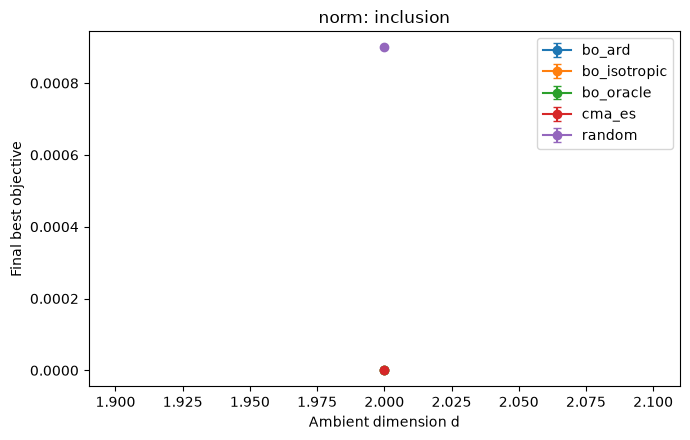

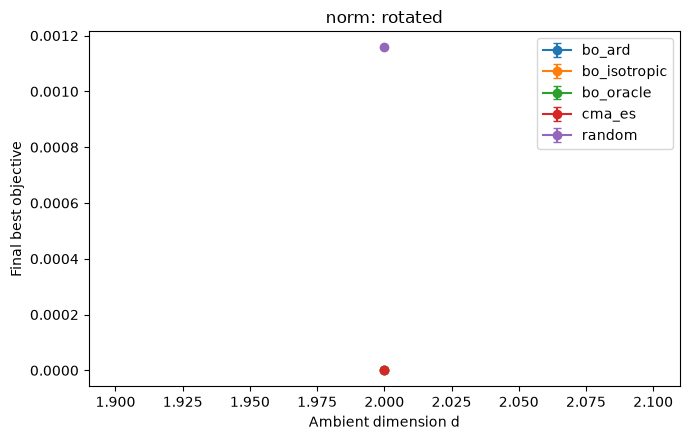

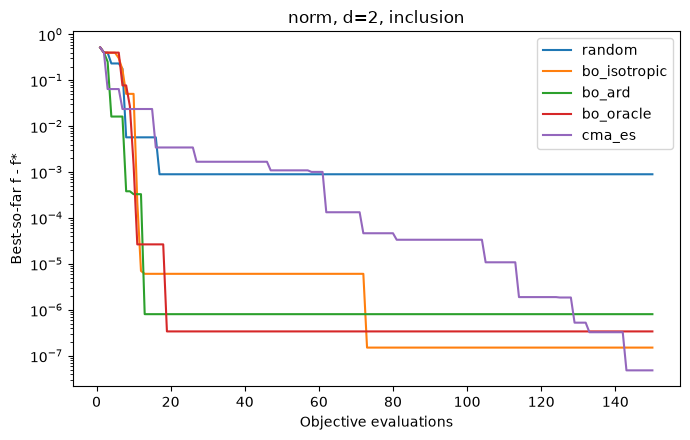

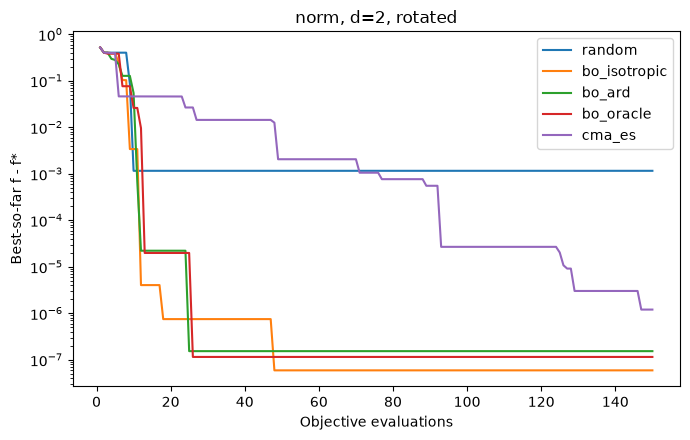

In [16]:
records = load_all_runs(cfg.data_dir)
print('Loaded completed runs:', len(records))
if records:
    display(final_summary(records).head())
    plot_final_vs_dimension(records, cfg.data_dir)
    plot_gap_vs_evaluations(records, cfg.data_dir)

## 16. Pilot diagnostics worth checking

The raw files support additional checks without rerunning optimization:

- runtime vs `d` and solver;
- BO SLSQP fallback rate and near-duplicate rate;
- isotropic/ARD/oracle fitted length scales over BO iterations;
- CMA-ES projection fraction by generation;
- CMA-ES mean, step size and covariance evolution;
- initial best objective vs `d` to expose high-dimensional unit-ball concentration effects;
- distribution of `A.T @ X_init` for norm and Branin instances.

These should be treated as diagnostics first; the pilot has intentionally few rotated instances and is not intended for strong statistical conclusions.

## 17. Run an instance and plot only that
This section is to test instances and pilot new changes to the code.

In [17]:
def find_run_spec(
    problems,
    run_specs,
    objective,
    d,
    embedding,
    A_index,
    init_index,
    solver,
):
    matches = [
        spec for spec in run_specs
        if (
            problems[spec.problem_id].objective_name == objective
            and problems[spec.problem_id].d == d
            and problems[spec.problem_id].embedding == embedding
            and problems[spec.problem_id].A_index == A_index
            and problems[spec.problem_id].init_index == init_index
            and spec.solver == solver
        )
    ]

    if len(matches) != 1:
        raise ValueError(f"Expected 1 match, found {len(matches)}")

    return matches[0]


def plot_single_run(problem, spec, result):
    # Initial evaluations + solver evaluations
    y_all = np.concatenate([
        problem.y_init,
        result['y_new']
    ])

    # Best objective observed up to each evaluation
    best_f = np.minimum.accumulate(y_all)

    # Global minimum
    if problem.objective_name == "norm":
        f_min = 0.0
    elif problem.objective_name == "branin":
        f_min = 0.39788735772973816
    else:
        raise ValueError(f"Unknown objective: {problem.objective_name}")

    gap = best_f - f_min
    evaluations = np.arange(1, len(y_all) + 1)

    plt.figure(figsize=(7, 4))
    plt.plot(evaluations, gap)

    plt.xlabel("Number of objective evaluations")
    plt.ylabel(r"Best $f - f_{\min}$")
    plt.title(
        f"{problem.objective_name} | "
        f"d={problem.d} | "
        f"{problem.embedding} A{problem.A_index} | "
        f"{spec.solver}"
    )

    plt.yscale("log")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

In [18]:
spec = find_run_spec(
    problems,
    run_specs,
    objective="branin",
    d=20,
    embedding="rotated",
    A_index=1,
    init_index=0,
    solver="bo_ard",
)

problem = problems[spec.problem_id]

ValueError: Expected 1 match, found 0

### Check if gradient implementation is working

In [ ]:
# Test analytic EI gradient before running full BO

X_obs = problem.X_init.copy()
y_obs = problem.y_init.copy()

if spec.solver == "bo_isotropic":
    ard = False
    oracle = False
    d_model = problem.d

elif spec.solver == "bo_ard":
    ard = True
    oracle = False
    d_model = problem.d

elif spec.solver == "bo_oracle":
    ard = False
    oracle = True
    d_model = problem.k

else:
    raise ValueError("Gradient test only applies to BO solvers.")

gp = make_gp(
    d_model=d_model,
    ard=ard,
    cfg_bo=cfg.bo,
    seed=spec.solver_seed,
)

X_model = transform_for_gp(problem, X_obs, oracle=oracle)
gp.fit(X_model, y_obs)

# Test analytic EI gradient at multiple random points

n_test_points = 20
rng_test = np.random.default_rng(123)

X_test = sample_unit_ball(
    n_test_points,
    problem.d,
    rng_test
)

results = []

for i, x_test in enumerate(X_test):

    def f_only(x):
        if oracle:
            x_model = x @ problem.A
        else:
            x_model = x

        value, _ = neg_ei_with_grad(
            x_model,
            gp,
            np.min(y_obs)
        )
        return value

    def grad_only(x):
        if oracle:
            z = x @ problem.A

            _, grad_z = neg_ei_with_grad(
                z,
                gp,
                np.min(y_obs)
            )

            # Chain rule back to ambient x-space
            return problem.A @ grad_z

        _, grad = neg_ei_with_grad(
            x,
            gp,
            np.min(y_obs)
        )
        return grad

    value = f_only(x_test)
    grad = grad_only(x_test)

    error = check_grad(
        f_only,
        grad_only,
        x_test
    )

    results.append({
        "point": i,
        "neg_EI": value,
        "grad_norm": np.linalg.norm(grad),
        "check_grad_error": error,
    })


gradient_test = pd.DataFrame(results)

display(gradient_test)

print("\nSummary")
print("------------------------------")
print("Max error:   ", gradient_test["check_grad_error"].max())
print("Mean error:  ", gradient_test["check_grad_error"].mean())
print("Median error:", gradient_test["check_grad_error"].median())


,point,neg_EI,grad_norm,check_grad_error
0,0,-8.624325e-212,0.000000e+00,0.000000e+00
1,1,-0.000000e+00,0.000000e+00,0.000000e+00
2,2,-3.840029e-238,0.000000e+00,0.000000e+00
3,3,-5.506415e+00,6.950633e+01,1.863973e-04
4,4,-4.084588e-51,8.893219e-48,6.802016e-52
5,5,-4.738549e-100,7.444490e-97,2.433596e-101
6,6,-6.746022e-08,1.336652e-05,4.000573e-10
7,7,-1.006595e-44,7.140986e-42,2.853268e-46
8,8,-1.063107e-154,3.394148e-151,1.038381e-155
9,9,-1.257535e-10,3.159610e-08,4.537433e-13



Summary
------------------------------
Max error:    0.00018639733014362157
Mean error:   9.321973110106104e-06
Median error: 5.045816833419281e-49
